# PRIDE API Tutorial

This Jupyter Notebook will walk you through how to find proteomics datasets in the ProteomeXchange Consortium database. 

### Step 1: Importing Libraries 

To get started, we need to import the necessary libraries:
- `requests` to make HTTP requests to the API.
- `pprint` to display the results in a readable format.

In [2]:
import requests
import pprint

### Step 2: Setting up the API url and query parameters

We will use the Omics Discovery Index (OmicsDI) to search for datasets across all ProteomeXchange repositories (PRIDE, MassIVE, jPOST, iProX, etc.).

In [3]:
base_url = "https://www.omicsdi.org/ws/dataset/search"
species_name = "Borrelia burgdorferi"

# OmicsDI allows a general query string.
# We filter by 'omics_type:Proteomics' to exclude non-proteomics data
params = {
    "query": f'"{species_name}" AND omics_type:"Proteomics"',
    "size": 100,  # Number of results to return --> increase this if you expect more
    "start": 0,
}


### Step 3: Making the GET request

Here, we use the 'requests.get' method to make the API request with the specified parameters. We also check if the request was successful.

In [4]:
datasets = None

try:
    response = requests.get(base_url, params=params)
    response.raise_for_status()
    data = response.json()

    datasets = data.get("datasets", [])

    if not datasets:
        print(f"No datasets found for {species_name}.")

    print(f"Found {data['count']} datasets across all repositories.\n")
    
except requests.exceptions.RequestException as e:
    print(f"Error connecting to OmicsDI: {e}")
    
pprint.pprint(datasets)

Found 31 datasets across all repositories.

[{'citationsCount': 0,
  'citationsCountScaled': 0.0,
  'claimable': False,
  'connectionsCount': 0,
  'connectionsCountScaled': 0.0,
  'description': 'To identify the effect of a CRISPR interference knockdown of '
                 'Borrelia burgdorferi strain B31 BB0838, a outer membrane '
                 'lipoprotein flippase candidate, on surface lipoprotein '
                 'secretion using Multidimensional Protein Identification '
                 'Technology.',
  'downloadCount': 0,
  'downloadCountScaled': 0.0,
  'id': 'MSV000089990',
  'keywords': None,
  'omicsType': ['Proteomics'],
  'organisms': [{'acc': '',
                 'name': 'Borrelia Burgdorferi B31 (ncbitaxon:224326)'}],
  'publicationDate': '20220727',
  'reanalysisCount': 0,
  'reanalysisCountScaled': 0.0,
  'score': None,
  'source': 'massive',
  'title': 'Identification of the effect of a CRISPR interference knockdown of '
           'Borrelia burgdorferi strain B3

### Step 4: Parsing the datasets and extracting relevant information


In [5]:
results_list = []

print(f"{'ID':<15} | {'Repository':<10} | {'Title':<52} | {'Year'} | {'Species'}")
print("-" * 130)

for ds in datasets:
    # OmicsDI returns the source DB (e.g., 'pride', 'massive') and the ID
    accession = ds["id"]
    database = ds["source"]
    title = ds["title"]
    species = ds["organisms"]
    date = ds["publicationDate"]

    results_list.append((accession, database))

    # Truncate title for cleaner printing
    short_title = (title[:50] + "..") if len(title) > 50 else title

    # Extract year from publication date
    year = date[:4] if date else "N/A"

    # Extract species name(s) as a comma-separated string
    if isinstance(species, list) and species and "name" in species[0]:
        species_str = ", ".join([org["name"] for org in species if "name" in org])
    else:
        species_str = str(species)

    print(f"{accession:<15} | {database:<10} | {short_title:<52} | {year} | {species_str}")

# Count datasets per source
import collections
source_counts = collections.Counter([db for _, db in results_list])
print("\nDatasets per source:")
for source, count in source_counts.items():
    print(f"{source}: {count}")

ID              | Repository | Title                                                | Year | Species
----------------------------------------------------------------------------------------------------------------------------------
MSV000089990    | massive    | Identification of the effect of a CRISPR interfere.. | 2022 | Borrelia Burgdorferi B31 (ncbitaxon:224326)
PXD010065       | pride      | Acetylation in Borrelia burgdorferi                  | 2018 | Borrelia burgdorferi B31
PXD007904       | pride      | Lipid rafts can form in the inner and outer membra.. | 2018 | Caenorhabditis elegans
PXD002365       | pride      | The Lipid Raft Proteome of Borrelia burgdorferi.     | 2015 | Borrelia burgdorferi B31
PXD023940       | pride      | Borrelia burgdorferi infected Ixodes scapularis ny.. | 2021 | Ixodes scapularis (Black-legged tick) (Deer tick), Borreliella burgdorferi, Oryctolagus cuniculus (Rabbit)
MSV000084408    | massive    | Tandem Mass Tags of Borrelia burgdorferi B31 der

In [ ]:
import csv

# Write summary to CSV
with open("borrelia_datasets_summary.csv", "w", newline='', encoding='utf-8') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(["ID", "Repository", "Title", "Year", "Species"])
    for ds in datasets:
        accession = ds["id"]
        database = ds["source"]
        title = ds["title"]
        date = ds["publicationDate"]
        species = ds["organisms"]
        # Extract species name(s) as a comma-separated string
        if isinstance(species, list) and species and "name" in species[0]:
            species_str = ", ".join([org["name"] for org in species if "name" in org])
        else:
            species_str = str(species)
        # Extract year from publication date
        year = date[:4] if date else "N/A"
        writer.writerow([accession, database, title, year, species_str])

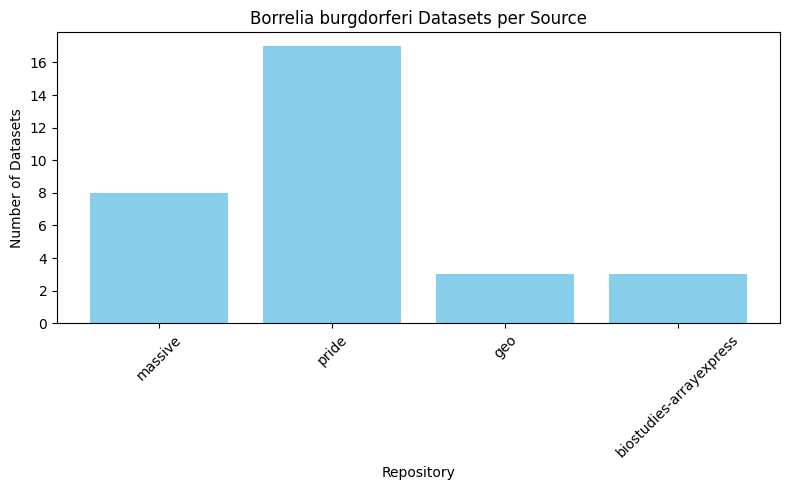

In [ ]:
import matplotlib.pyplot as plt

# Plotting the dataset counts per source
sources = list(source_counts.keys())
counts = list(source_counts.values())

plt.figure(figsize=(8, 5))
plt.bar(sources, counts, color='skyblue')
plt.xlabel('Repository')
plt.ylabel('Number of Datasets')
plt.title('Borrelia burgdorferi Datasets per Source')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("borrelia_datasets_count.jpg", dpi=300)  # Save the figure as a .jpg file
plt.show()